# Mode-aware behavior association: reproducible exploratory study

This notebook reads aggregate results generated from the pinned public trace subset. It reports task-held-out retrieval and the incremental effect of adding **out-of-fold execution-mode scores** to a same-task association ranker. It never prints raw commands or tool arguments.

**Scope:** the positive label is the same CTF challenge ID, not a shared intrusion, operator, campaign, or APT actor. Human terminal transcripts and Agent tool-call records come from different capture pathways. The mode score is therefore a public-record modality proxy, not a validated real-world human/Agent detector. Fixed scripts are not represented in the data.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
cross = json.loads((ROOT / "results/crossbenchmark_exploration.json").read_text())
proto = json.loads((ROOT / "results/mode_aware_association.json").read_text())
print("Dataset revision:", cross["dataset_revision"])
print("Independent groups:", proto["audit"]["tasks"], "across", proto["audit"]["tasks_by_benchmark"])
print("Trace rows:", proto["audit"]["records"])

Dataset revision: 178c0da1800f9c07311e1b8d6c61dd8104e7b4ae
Independent groups: 40 across {'intercode-ctf': 27, 'cybench': 6, 'nyuctf': 7}
Trace rows: 177


## What the prototype does

It has two heads. The mode head scores a trace as **human-like** or **Agent-like** using command TF-IDF and balanced logistic regression. The association head ranks candidate task matches from command similarity and ordered coarse-action bigrams; it can condition those features on the mode head's probability and interactions. Mode scores for association training traces are cross-fitted within the outer training split, so each training score comes from a model that did not see that task.

Pair training uses balanced, task-sampled positive/negative pairs and negatives from different tasks in the same benchmark. Outer evaluation holds out complete task IDs. The “oracle” row uses the known human/Agent labels and is a diagnostic upper bound only. All pair scores are ranking scores under balanced pair sampling; they are not calibrated real-world probabilities.

In [2]:
def fmt_ci(value, ci):
    return f"{value:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]"

retrieval_rows = []
for method, label, source in [
    ("command_unigram", "Command unigram cosine", cross["retrieval"]),
    ("ordered_action_bigram", "Ordered action bigram cosine", cross["retrieval"]),
    ("procgrep_local_patterns", "ProcGrep local patterns", cross["retrieval"]),
]:
    item = source[f"{method}|human_agent"]
    retrieval_rows.append({
        "Method": label,
        "Recall@1 (95% task CI)": fmt_ci(item["benchmark_macro"]["recall_at_1"], item["task_stratified_95_ci"]["recall_at_1"]),
        "MRR": item["benchmark_macro"]["mrr"],
        "Query AUC": item["benchmark_macro"]["query_auc"],
    })
for method, label in [
    ("similarity_only", "Pairwise similarity ranker"),
    ("mode_aware", "Mode-aware ranker (OOF mode score)"),
    ("oracle_mode_upper_bound", "Oracle mode labels (diagnostic only)"),
]:
    item = proto["retrieval"][f"human_agent|{method}"]
    retrieval_rows.append({
        "Method": label,
        "Recall@1 (95% task CI)": fmt_ci(item["benchmark_macro"]["recall_at_1"], item["task_stratified_95_ci"]["recall_at_1"]),
        "MRR": item["benchmark_macro"]["mrr"],
        "Query AUC": item["benchmark_macro"]["query_auc"],
    })
retrieval_table = pd.DataFrame(retrieval_rows)
display(retrieval_table.style.format({"MRR":"{:.3f}", "Query AUC":"{:.3f}"}))

,Method,Recall@1 (95% task CI),MRR,Query AUC
0,Command unigram cosine,"0.347 [0.165, 0.536]",0.518,0.740
1,Ordered action bigram cosine,"0.414 [0.245, 0.576]",0.561,0.733
2,ProcGrep local patterns,"0.287 [0.123, 0.451]",0.484,0.706
3,Pairwise similarity ranker,"0.346 [0.175, 0.521]",0.538,0.760
4,Mode-aware ranker (OOF mode score),"0.414 [0.231, 0.597]",0.577,0.775
5,Oracle mode labels (diagnostic only),"0.346 [0.170, 0.527]",0.538,0.759


## Does mode information improve association?

The paired change uses the same held-out task groups for both rankers, with a stratified task-cluster bootstrap. A confidence interval crossing zero means this experiment does not establish a reliable gain. Human–human results use fewer independent tasks because most tasks lack multiple human records.

In [3]:
delta_rows = []
for direction, label in [
    ("human_agent", "Human → Agent"),
    ("agent_agent_cross_model", "Agent → Agent, cross-model"),
    ("agent_human", "Agent → Human"),
    ("human_human", "Human → Human"),
]:
    row = {"Query direction": label}
    for metric in ("recall_at_1", "mrr", "query_auc"):
        x = proto["paired_delta_mode_aware_minus_similarity_only"][f"{direction}|{metric}"]
        row[metric] = f"{x['mean_delta']:+.3f} [{x['task_stratified_95_ci'][0]:+.3f}, {x['task_stratified_95_ci'][1]:+.3f}]"
        row["Independent tasks"] = x["task_count"]
    delta_rows.append(row)
delta_table = pd.DataFrame(delta_rows)
display(delta_table)

,Query direction,recall_at_1,Independent tasks,mrr,query_auc
0,Human → Agent,"+0.068 [-0.012, +0.191]",40,"+0.039 [-0.006, +0.100]","+0.015 [-0.005, +0.040]"
1,"Agent → Agent, cross-model","+0.012 [-0.016, +0.051]",40,"+0.008 [-0.009, +0.030]","+0.011 [-0.007, +0.033]"
2,Agent → Human,"+0.024 [-0.012, +0.068]",40,"+0.021 [-0.006, +0.055]","+0.014 [-0.017, +0.044]"
3,Human → Human,"-0.098 [-0.189, -0.007]",17,"-0.078 [-0.139, -0.019]","-0.045 [-0.079, -0.012]"


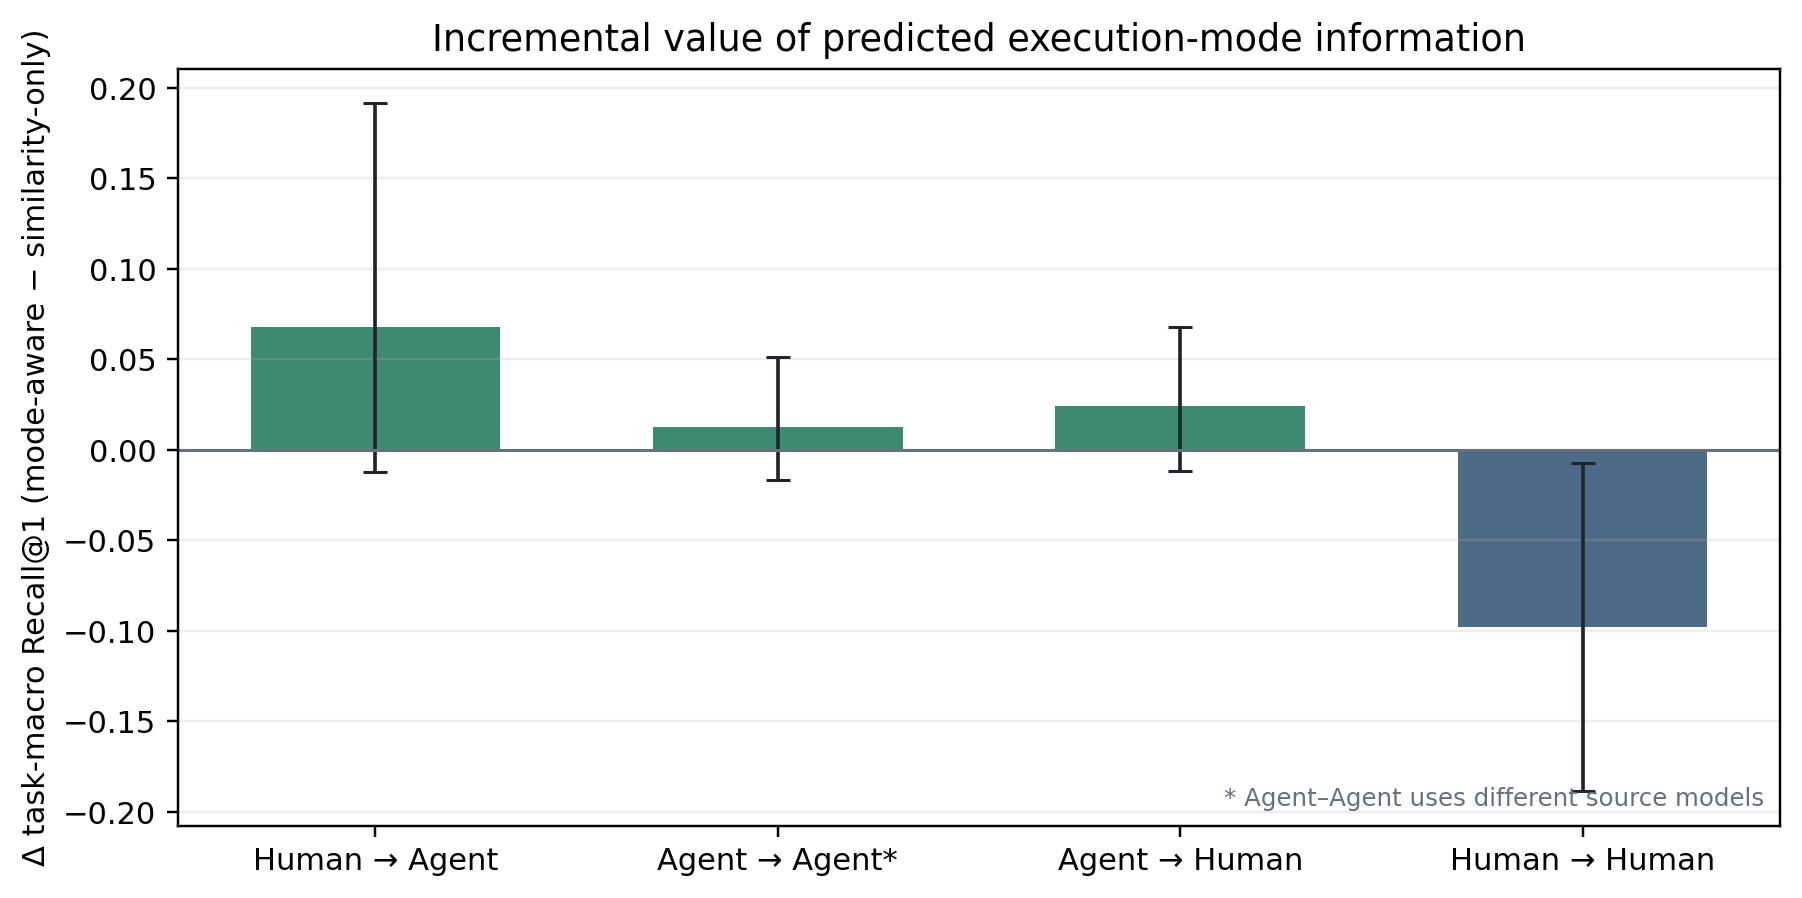

In [4]:
Image(filename=str(ROOT / "results/figures/mode_aware_association_delta.png"))

## Per-benchmark Human → Agent retrieval

The random baseline is the reciprocal of the number of candidate tasks, and therefore differs by benchmark. Results are task-macro averages; confidence intervals are pooled in the main table above, not interpreted as broad population estimates.

In [5]:
benchmark_rows = []
for method, label in [("similarity_only", "Similarity only"), ("mode_aware", "Mode-aware")]:
    item = proto["retrieval"][f"human_agent|{method}"]
    for benchmark, metrics in item["by_benchmark"].items():
        benchmark_rows.append({
            "Benchmark": benchmark,
            "Method": label,
            "Tasks": metrics["task_count"],
            "Recall@1": metrics["recall_at_1"],
            "Random R@1": metrics["random_recall_at_1"],
            "MRR": metrics["mrr"],
            "Query AUC": metrics["query_auc"],
        })
display(pd.DataFrame(benchmark_rows).style.format({"Recall@1":"{:.3f}", "Random R@1":"{:.3f}", "MRR":"{:.3f}", "Query AUC":"{:.3f}"}))

,Benchmark,Method,Tasks,Recall@1,Random R@1,MRR,Query AUC
0,cybench,Similarity only,6,0.333,0.167,0.625,0.817
1,intercode-ctf,Similarity only,27,0.204,0.037,0.322,0.678
2,nyuctf,Similarity only,7,0.500,0.143,0.667,0.786
3,cybench,Mode-aware,6,0.500,0.167,0.708,0.850
4,intercode-ctf,Mode-aware,27,0.241,0.037,0.356,0.689
5,nyuctf,Mode-aware,7,0.500,0.143,0.667,0.786


## Mode-head result and confound boundary

The mode head's score is evaluated on outer-fold tasks. It predicts whether a record came from the study's human terminal pathway or one of the selected Agent tool-call pathways. Because capture method is tied to label, this is not evidence that command logs can identify the real decision-maker.

In [6]:
mode = proto["mode_head"]
mode_table = pd.DataFrame([{
    "Records": mode["n"],
    "Task-held-out balanced accuracy": mode["balanced_accuracy"],
    "95% task CI": fmt_ci(mode["balanced_accuracy"], mode["task_stratified_95_ci"]["balanced_accuracy"]),
    "Macro-F1": mode["macro_f1"],
    "ROC-AUC": mode["roc_auc"],
}])
display(mode_table.style.format({"Task-held-out balanced accuracy":"{:.3f}", "Macro-F1":"{:.3f}", "ROC-AUC":"{:.3f}"}))
display(pd.DataFrame.from_dict(mode["by_benchmark"], orient="index"))

,Records,Task-held-out balanced accuracy,95% task CI,Macro-F1,ROC-AUC
0,177,0.871,"0.871 [0.820, 0.919]",0.861,0.947


,records,balanced_accuracy,macro_f1,roc_auc
cybench,26,0.854167,0.830065,0.958333
intercode-ctf,121,0.894444,0.882128,0.964352
nyuctf,30,0.785714,0.794802,0.917989


## Rebuild and validation

From the repository root, install the pinned Python dependencies, download the selected traces, then run both experiment scripts. The downloader verifies each file against the pinned byte count and SHA-256. Raw logs remain under ignored `data/raw/`; result files contain aggregate metrics and task IDs, not raw commands.

```bash
.venv/bin/pip install -r requirements.lock.txt
.venv/bin/python scripts/download_public_traces.py
.venv/bin/python scripts/download_crossbenchmark_traces.py
.venv/bin/python scripts/run_crossbenchmark_experiments.py
.venv/bin/python scripts/run_mode_aware_association.py
.venv/bin/python -m unittest discover -s tests
```

In [7]:
# Verify the saved result structure and task-disjoint outer folds.
assert proto["audit"]["records"] == 177
assert proto["audit"]["tasks"] == 40
for fold in proto["folds"]:
    assert set(fold["train_task_ids"]).isdisjoint(fold["test_task_ids"])
assert len(set().union(*(set(f["test_task_ids"]) for f in proto["folds"]))) == 40
assert all(proto["retrieval"][f"human_agent|{method}"]["task_count"] == 40
           for method in ("similarity_only", "mode_aware", "oracle_mode_upper_bound"))
print("Result counts, held-out task disjointness, and retrieval coverage verified.")

Result counts, held-out task disjointness, and retrieval coverage verified.


## Interpretation for the paper

This public-trace experiment establishes that challenge-level behavioral retrieval is measurable above random within these three selected benchmarks. The mode-aware ranker improves the Human→Agent Recall@1 point estimate by about 0.07, but its paired task-cluster interval crosses zero; other directions are neutral or show a loss for Human→Human retrieval. Therefore, these results do **not** establish that Agent participation breaks association or that detecting mode restores it. The defensible contribution is a falsifiable prototype and a data-quality result: mode-aware scoring may help mixed-mode matching, but the effect is not yet stable and must be retested with common telemetry, repeated human/script/Agent runs, and independent activity labels.